In [8]:
!pip install timm -q

# Import essential libraries for deep learning-based bone age prediction:
# PyTorch & timm for CNN models, OpenCV for image processing,
# sklearn for metrics, and matplotlib/seaborn for visualization

In [9]:
# ==========================================
# IMPORTS
# ==========================================
import os
import gc
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, accuracy_score, precision_score, 
                             recall_score, f1_score, cohen_kappa_score, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

print("All imports successful")

All imports successful


# Project paths, image sizes (512→299), and device setup (MPS for Apple Silicon).
# seed_everything() ensures reproducible results across all random operations.

In [10]:
# ==========================================
# CONFIGURATION (Mac M1 Optimized)
# ==========================================
gc.collect()

class Config:
    DATA_DIR = '/Users/ashrithyathin/Downloads/PRML/dataset'
    MODEL_DIR = '/Users/ashrithyathin/Downloads/PRML/models'
    LOAD_SIZE = 512      # Load high-res for better crops
    CROP_SIZE = 299      # Input size for Xception/ResNet
    BATCH_SIZE = 16      
    # Mac M1: Use MPS (Metal Performance Shaders) instead of CUDA
    DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
    SEED = 42

def seed_everything(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(Config.SEED)

print(f"Device: {Config.DEVICE}")
print(f"MPS Available: {torch.backends.mps.is_available()}")
print(f"Data Directory: {Config.DATA_DIR}")
print(f"Model Directory: {Config.MODEL_DIR}")

Device: mps
MPS Available: True
Data Directory: /Users/ashrithyathin/Downloads/PRML/dataset
Model Directory: /Users/ashrithyathin/Downloads/PRML/models


# Custom PyTorch Dataset that extracts two anatomical regions from each X-ray:
# - Region A (top 70%): Metacarpal/fingers → fed to ResNet
# - Region B (bottom 40%): Carpal/wrist → fed to Xception
# Data is split 80/20, normalized with ImageNet stats, and loaded with num_workers=0 for Mac compatibility.

In [11]:
# ==========================================
# DATASET (Dual-Input with Heuristic Cropping)
# ==========================================
class TwoStageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]  # ← Need 4 more spaces here
        image_path = row['path']
        
        # Load High-Res Image
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (Config.LOAD_SIZE, Config.LOAD_SIZE))
        
        h, w, _ = image.shape
        
        # Region A: Metacarpal (Fingers) -> For ResNet
        metacarpal_img = image[0:int(h*0.7), 0:w] 
        
        # Region B: Carpal (Wrist) -> For Xception
        carpal_img = image[int(h*0.6):h, 0:w] 
        
        # Apply Transforms
        if self.transform:
            metacarpal_img = self.transform(metacarpal_img)
            carpal_img = self.transform(carpal_img)
            
        age = torch.tensor(row['boneage'], dtype=torch.float32)
        gender = torch.tensor(row['gender_encoded'], dtype=torch.float32)
        
        return carpal_img, metacarpal_img, gender, age

# Load and prepare data
print(f"Loading data from {Config.DATA_DIR}...")
df = pd.read_csv(os.path.join(Config.DATA_DIR, 'boneage-training-dataset.csv'))
df['gender_encoded'] = df['male'].astype(float)
df['path'] = df['id'].apply(lambda x: os.path.join(Config.DATA_DIR, 'boneage-training-dataset', 'boneage-training-dataset', f'{x}.png'))
# Split data
train_df, val_df = train_test_split(df, test_size=0.2, random_state=Config.SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")

# Data transforms
data_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((Config.CROP_SIZE, Config.CROP_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_loader = DataLoader(
    TwoStageDataset(train_df, data_transform), 
    batch_size=Config.BATCH_SIZE, 
    shuffle=True, 
    num_workers=0,  # ← CHANGE THIS FROM 2 TO 0
    pin_memory=False
)

val_loader = DataLoader(
    TwoStageDataset(val_df, data_transform), 
    batch_size=Config.BATCH_SIZE, 
    shuffle=False, 
    num_workers=0,  # ← CHANGE THIS FROM 2 TO 0
    pin_memory=False
)
print("Datasets and DataLoaders ready")

Loading data from /Users/ashrithyathin/Downloads/PRML/dataset...
Training samples: 10088
Validation samples: 2523
Datasets and DataLoaders ready


# SSL Certificate Workaround
# Bypasses SSL verification errors when downloading pre-trained models from PyTorch Hub.
# Required on some systems (especially Mac) where default certificates fail to verify.

In [12]:
import ssl
import urllib.request

ssl._create_default_https_context = ssl._create_unverified_context

import certifi
ssl_context = ssl.create_default_context(cafile=certifi.where())
ssl_context.check_hostname = False
ssl_context.verify_mode = ssl.CERT_NONE

https_handler = urllib.request.HTTPSHandler(context=ssl_context)
opener = urllib.request.build_opener(https_handler)
urllib.request.install_opener(opener)

print("SSL certificate workaround applied (downloading from PyTorch Hub will work)")

SSL certificate workaround applied (downloading from PyTorch Hub will work)


# Two-stream CNN architecture combining anatomical region-specific networks:
# - Stream 1: Xception processes carpal (wrist) region
# - Stream 2: ResNet50 processes metacarpal (finger) region
# Features are concatenated with gender embedding and passed through a regression head.

In [13]:
# ==========================================
# MODEL DEFINITION (Dual Stream)
# ==========================================
class TrueStage2Network(nn.Module):
    def __init__(self):
        super(TrueStage2Network, self).__init__()
        
        # Stream 1: Carpal (Wrist) -> Xception
        self.carpal_net = timm.create_model('xception', pretrained=True, num_classes=0)
        
        # Stream 2: Metacarpal (Fingers) -> ResNet50
        self.meta_net = timm.create_model('resnet50', pretrained=True, num_classes=0)
        
        # Fusion
        self.concat_dim = self.carpal_net.num_features + self.meta_net.num_features
        self.gender_fc = nn.Linear(1, 32)
        
        self.regressor = nn.Sequential(
            nn.Linear(self.concat_dim + 32, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 1)
        )
        
    def forward(self, carpal_img, meta_img, gender):
        # Forward pass for training
        carpal_feat = self.carpal_net(carpal_img)
        meta_feat = self.meta_net(meta_img)
        
        img_feat = torch.cat((carpal_feat, meta_feat), dim=1)
        gender_feat = self.gender_fc(gender.unsqueeze(1))
        
        combined = torch.cat((img_feat, gender_feat), dim=1)
        return self.regressor(combined).squeeze()

print("Initializing TrueStage2Network...")
model = TrueStage2Network()
print(f"Model initialized")
print(f"   Carpal features: {model.carpal_net.num_features}")
print(f"   Meta features: {model.meta_net.num_features}")
print(f"   Total concat dim: {model.concat_dim}")

Initializing TrueStage2Network...


/Users/ashrithyathin/Downloads/PRML/bone_env/lib/python3.12/site-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Model initialized
   Carpal features: 2048
   Meta features: 2048
   Total concat dim: 4096


# Loads pre-trained weights from saved checkpoint file.
# Handles DataParallel wrapper by stripping "module." prefix if present.
# Falls back to untrained model if weights file is missing.

In [14]:
# ==========================================
# LOAD TRAINED MODEL WEIGHTS
# ==========================================
model_path = os.path.join(Config.MODEL_DIR, 'best_two_stage_model.pth')

print(f"Loading model weights from: {model_path}")

if os.path.exists(model_path):
    try:
        # Load state dict
        state_dict = torch.load(model_path, map_location=Config.DEVICE)
        
        # Handle potential DataParallel wrapper (remove "module." prefix if present)
        new_state_dict = {}
        for k, v in state_dict.items():
            name = k.replace("module.", "") if k.startswith("module.") else k
            new_state_dict[name] = v
        
        model.load_state_dict(new_state_dict)
        print("Model weights loaded successfully")
    except Exception as e:
        print(f"Error loading model: {e}")
        print("   Proceeding with untrained model for demonstration")
else:
    print(f"Model file not found at {model_path}")
    print("   Please ensure you have trained the model and saved it to this location")
    print("   Proceeding with untrained model for demonstration")

# Move model to device
model = model.to(Config.DEVICE)
model.eval()
print(f"Model ready on {Config.DEVICE}")

Loading model weights from: /Users/ashrithyathin/Downloads/PRML/models/best_two_stage_model.pth
Model weights loaded successfully
Model ready on mps


In [15]:
"""

class TrueStage2Network(nn.Module):
    def __init__(self):
        super(TrueStage2Network, self).__init__()
        
        # Stream 1: Carpal (Wrist) -> Xception
        self.carpal_net = timm.create_model('xception', pretrained=True, num_classes=0)
        
        # Stream 2: Metacarpal (Fingers) -> ResNet50
        self.meta_net = timm.create_model('resnet50', pretrained=True, num_classes=0)
        
        # Fusion
        self.concat_dim = self.carpal_net.num_features + self.meta_net.num_features
        self.gender_fc = nn.Linear(1, 32)
        
        self.regressor = nn.Sequential(
            nn.Linear(self.concat_dim + 32, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 1)
        )
        
    def forward(self, carpal_img, meta_img, gender):
        # Forward pass for training
        carpal_feat = self.carpal_net(carpal_img)
        meta_feat = self.meta_net(meta_img)
        
        img_feat = torch.cat((carpal_feat, meta_feat), dim=1)
        gender_feat = self.gender_fc(gender.unsqueeze(1))
        
        combined = torch.cat((img_feat, gender_feat), dim=1)
        return self.regressor(combined).squeeze()

    # Specialized forward methods for Grad-CAM
    def forward_carpal(self, x):
        return self.carpal_net(x)

    def forward_meta(self, x):
        return self.meta_net(x)

# Initialize
print("Initializing True Two-Stage Model...")
model = TrueStage2Network()

# --- PRINT ARCHITECTURE ---
print("\n" + "="*30)
print("MODEL ARCHITECTURE")
print("="*30)
print(model)
print("="*30 + "\n")

if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs")
    model = nn.DataParallel(model)
    
model = model.to(Config.DEVICE)
print(f"Model moved to {Config.DEVICE}")

# Loss function and optimizer
criterion = nn.L1Loss()  # Mean Absolute Error
optimizer = torch.optim.Adam(model.parameters(), lr=Config.LR)

# Learning rate scheduler (optional but recommended)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.5, 
    patience=3, 
    verbose=True
)

print("Training setup complete")
print(f"Loss function: {criterion}")
print(f"Optimizer: Adam with LR={Config.LR}")

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    
    pbar = tqdm(loader, desc='Training')
    for carpal_imgs, meta_imgs, genders, ages in pbar:
        carpal_imgs = carpal_imgs.to(device)
        meta_imgs = meta_imgs.to(device)
        genders = genders.to(device)
        ages = ages.to(device)
        
        # Forward pass
        optimizer.zero_grad()
        outputs = model(carpal_imgs, meta_imgs, genders)
        loss = criterion(outputs, ages)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * carpal_imgs.size(0)
        pbar.set_postfix({'loss': loss.item()})
        
    epoch_loss = running_loss / len(loader.dataset)
    return epoch_loss

def validate_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_ages = []
    
    with torch.no_grad():
        pbar = tqdm(loader, desc='Validation')
        for carpal_imgs, meta_imgs, genders, ages in pbar:
            carpal_imgs = carpal_imgs.to(device)
            meta_imgs = meta_imgs.to(device)
            genders = genders.to(device)
            ages = ages.to(device)
            
            outputs = model(carpal_imgs, meta_imgs, genders)
            loss = criterion(outputs, ages)
            
            running_loss += loss.item() * carpal_imgs.size(0)
            all_preds.extend(outputs.cpu().numpy())
            all_ages.extend(ages.cpu().numpy())
            
            pbar.set_postfix({'loss': loss.item()})
    
    epoch_loss = running_loss / len(loader.dataset)
    
    # Calculate MAE in years
    mae_years = mean_absolute_error(np.array(all_ages) / 12.0, np.array(all_preds) / 12.0)
    
    return epoch_loss, mae_years

print("Training functions defined")

"""

'\n\nclass TrueStage2Network(nn.Module):\n    def __init__(self):\n        super(TrueStage2Network, self).__init__()\n\n        # Stream 1: Carpal (Wrist) -> Xception\n        self.carpal_net = timm.create_model(\'xception\', pretrained=True, num_classes=0)\n\n        # Stream 2: Metacarpal (Fingers) -> ResNet50\n        self.meta_net = timm.create_model(\'resnet50\', pretrained=True, num_classes=0)\n\n        # Fusion\n        self.concat_dim = self.carpal_net.num_features + self.meta_net.num_features\n        self.gender_fc = nn.Linear(1, 32)\n\n        self.regressor = nn.Sequential(\n            nn.Linear(self.concat_dim + 32, 1024),\n            nn.ReLU(),\n            nn.Dropout(0.5),\n            nn.Linear(1024, 512),\n            nn.ReLU(),\n            nn.Linear(512, 1)\n        )\n\n    def forward(self, carpal_img, meta_img, gender):\n        # Forward pass for training\n        carpal_feat = self.carpal_net(carpal_img)\n        meta_feat = self.meta_net(meta_img)\n\n       

# Evaluates the dual-stream model with three types of analysis:
# 1. Regression: MAE in years, separated by gender with bias gap reporting
# 2. Classification: Accuracy, F1, QWK for developmental stages (Toddler/Pre-Puberty/Puberty/Young Adult)
# 3. Visualization: Scatter plot, error distribution violin plots, and confusion matrix

In [16]:
# ==========================================
# COMPREHENSIVE ANALYSIS FUNCTION
# ==========================================

def analyze_model2_performance_full(model, loader, device):
    """
    Comprehensive Analysis for TrueStage2Network (Dual-Input Model).
    - Reports Regression Metrics (MAE) in YEARS.
    - Reports Classification Metrics (Acc, F1, QWK) based on developmental stages.
    """
    model.eval()
    
    # Store results separated by gender
    results = {
        'male': {'true': [], 'pred': []},
        'female': {'true': [], 'pred': []}
    }
    
    print("Running Inference on Dual-Stream Model...")
    with torch.no_grad():
        for carpal_imgs, meta_imgs, genders, ages in loader:
            carpal_imgs = carpal_imgs.to(device)
            meta_imgs = meta_imgs.to(device)
            genders = genders.to(device)
            
            # Predict
            p_age = model(carpal_imgs, meta_imgs, genders)
            
            # Convert to numpy
            batch_genders = genders.cpu().numpy().flatten()
            batch_ages = ages.numpy()
            batch_preds = p_age.cpu().view(-1).numpy()
            
            # Separate by Gender
            for i in range(len(batch_genders)):
                if batch_genders[i] >= 0.5: 
                    key = 'male'
                else:
                    key = 'female'
                results[key]['true'].append(batch_ages[i])
                results[key]['pred'].append(batch_preds[i])

    # ==========================================
    # PART 1: REGRESSION ANALYSIS (IN YEARS)
    # ==========================================
    print("\n" + "="*40)
    print("REGRESSION REPORT (in Years)")
    print("="*40)
    
    metrics = {}
    
    # Lists to aggregate all data for classification later
    all_true_years = []
    all_pred_years = []

    for sex in ['male', 'female']:
        # Convert months to years
        y_true = np.array(results[sex]['true']) / 12.0
        y_pred = np.array(results[sex]['pred']) / 12.0
        
        # Store for overall classification
        all_true_years.extend(y_true)
        all_pred_years.extend(y_pred)
        
        if len(y_true) == 0:
            print(f"[{sex.upper()}] No samples found.")
            metrics[sex] = {'mae': 0}
            continue

        mae = mean_absolute_error(y_true, y_pred)
        metrics[sex] = {'mae': mae}
        
        print(f"[{sex.upper()}] (n={len(y_true)})")
        print(f"  MAE:      {mae:.4f} years")
        print("-" * 40)
        
    if 'male' in metrics and 'female' in metrics:
        gap = abs(metrics['male']['mae'] - metrics['female']['mae'])
        print(f"BIAS GAP: {gap:.4f} years")

    # ==========================================
    # PART 2: CLASSIFICATION ANALYSIS
    # ==========================================
    # Helper to map Years -> Stage ID
    # 0: <3y (Toddler), 1: 3-10y (Pre-Puberty), 2: 10-15y (Puberty), 3: >15y (Young Adult)
    def get_stage_from_years(age_years):
        if age_years < 3.0: return 0
        elif age_years < 10.0: return 1
        elif age_years < 15.0: return 2
        else: return 3

    # Convert aggregated continuous years to discrete bins
    y_true_bins = [get_stage_from_years(y) for y in all_true_years]
    y_pred_bins = [get_stage_from_years(y) for y in all_pred_years]

    # --- METRICS CALCULATION ---
    acc = accuracy_score(y_true_bins, y_pred_bins)
    prec = precision_score(y_true_bins, y_pred_bins, average='weighted', zero_division=0)
    rec = recall_score(y_true_bins, y_pred_bins, average='weighted', zero_division=0)
    f1 = f1_score(y_true_bins, y_pred_bins, average='weighted', zero_division=0)
    qwk = cohen_kappa_score(y_true_bins, y_pred_bins, weights='quadratic')
    cm = confusion_matrix(y_true_bins, y_pred_bins)

    print("\n" + "="*40)
    print("CLASSIFICATION REPORT (Derived from Regression)")
    print("="*40)
    print(f"Accuracy:    {acc:.4f}")
    print(f"Precision:   {prec:.4f}")
    print(f"Recall:      {rec:.4f}")
    print(f"F1 Score:    {f1:.4f}")
    print(f"QWK (Kappa): {qwk:.4f}")
    print("-" * 40)
    print("Confusion Matrix:")
    print(cm)

    # ==========================================
    # PART 3: VISUALIZATION
    # ==========================================
    plt.figure(figsize=(18, 6))
    
    # Subplot 1: Regression Scatter
    plt.subplot(1, 3, 1)
    if len(results['male']['true']) > 0:
        plt.scatter(np.array(results['male']['true'])/12.0, np.array(results['male']['pred'])/12.0, 
                    alpha=0.4, label='Male', color='blue', s=20)
    if len(results['female']['true']) > 0:
        plt.scatter(np.array(results['female']['true'])/12.0, np.array(results['female']['pred'])/12.0, 
                    alpha=0.4, label='Female', color='red', s=20)
    plt.plot([0, 20], [0, 20], 'k--', lw=2, label='Ideal')
    plt.xlabel("Actual Age (Years)")
    plt.ylabel("Predicted Age (Years)")
    plt.title("Regression Fit")
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Subplot 2: Error Distribution
    plt.subplot(1, 3, 2)
    plot_data = []
    for sex in ['male', 'female']:
        if len(results[sex]['true']) > 0:
            errors = (np.array(results[sex]['pred']) - np.array(results[sex]['true'])) / 12.0
            for err in errors:
                plot_data.append({'Gender': sex.capitalize(), 'Error (Years)': err})
    df_plot = pd.DataFrame(plot_data)
    if not df_plot.empty:
        sns.violinplot(data=df_plot, x='Gender', y='Error (Years)', palette={'Male': 'blue', 'Female': 'red'}, alpha=0.5)
        plt.axhline(0, color='black', linestyle='--')
        plt.title("Error Distribution")
        plt.grid(True, axis='y', alpha=0.3)

    # Subplot 3: Confusion Matrix
    plt.subplot(1, 3, 3)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Toddler', 'Pre-Pub', 'Puberty', 'Y.Adult'],
                yticklabels=['Toddler', 'Pre-Pub', 'Puberty', 'Y.Adult'])
    plt.xlabel("Predicted Stage")
    plt.ylabel("True Stage")
    plt.title("Classification Matrix")

    plt.tight_layout()
    plt.show()
    
    print("\nAnalysis complete!")

print("Analysis function defined")

Analysis function defined


# Loads trained weights and runs inference on validation set.
# Computes regression metrics in years: MAE, RMSE, and R² score.
# Progress bar via tqdm shows batch processing status.

In [17]:
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

# Load the trained model
model_path = '/Users/ashrithyathin/Downloads/PRML/models/best_two_stage_model.pth'

print(f"Loading model from: {model_path}")
state_dict = torch.load(model_path, map_location=Config.DEVICE)

# Remove 'module.' prefix if present (from DataParallel)
new_state_dict = {}
for k, v in state_dict.items():
    name = k.replace("module.", "") if k.startswith("module.") else k
    new_state_dict[name] = v

model.load_state_dict(new_state_dict)
model.to(Config.DEVICE)
model.eval()
print("✓ Model loaded\n")

# Run inference on validation set
print("Running inference...")
all_true = []
all_pred = []

with torch.no_grad():
    # Add progress bar
    for carpal_imgs, meta_imgs, genders, ages in tqdm(val_loader, desc="Processing batches", unit="batch"):
        carpal_imgs = carpal_imgs.to(Config.DEVICE)
        meta_imgs = meta_imgs.to(Config.DEVICE)
        genders = genders.to(Config.DEVICE)
        
        pred_ages = model(carpal_imgs, meta_imgs, genders)
        
        all_true.extend(ages.numpy())
        all_pred.extend(pred_ages.cpu().numpy())

# Convert months to years
y_true = np.array(all_true) / 12.0
y_pred = np.array(all_pred) / 12.0

# Calculate metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

# Print results
print("\n" + "="*50)
print("FINAL METRICS")
print("="*50)
print(f"MAE:  {mae:.4f} years")
print(f"RMSE: {rmse:.4f} years")
print(f"R²:   {r2:.4f}")
print("="*50)

Loading model from: /Users/ashrithyathin/Downloads/PRML/models/best_two_stage_model.pth
✓ Model loaded

Running inference...


Processing batches: 100%|██████████| 158/158 [05:42<00:00,  2.17s/batch]


FINAL METRICS
MAE:  0.6624 years
RMSE: 0.8991 years
R²:   0.9343


# Scatter plot comparing predicted vs actual bone ages (in years).
# Diagonal dashed line represents perfect prediction; metrics displayed in title.

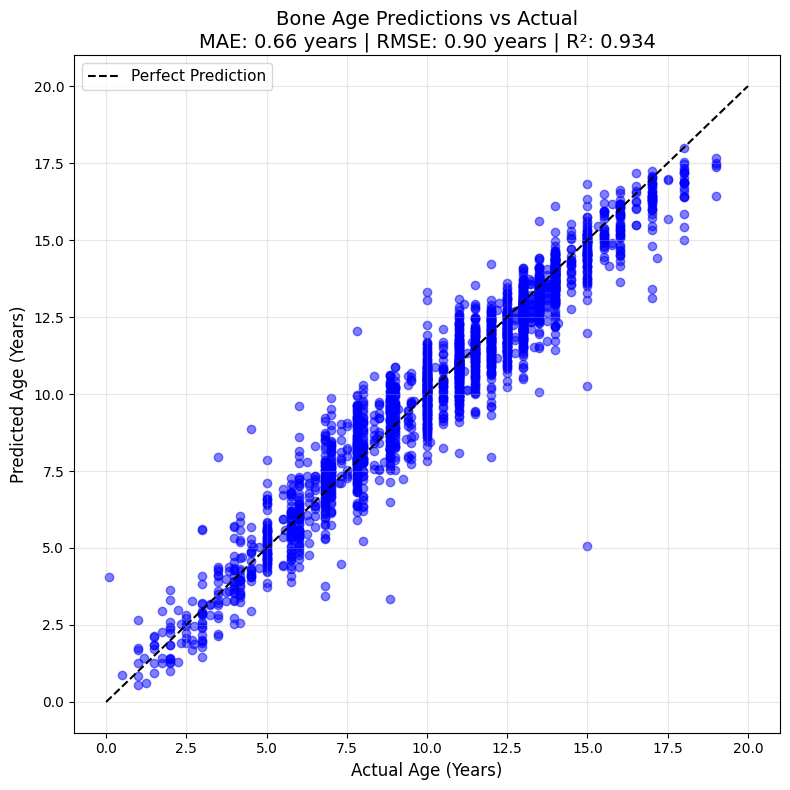

In [18]:
import matplotlib.pyplot as plt

# Create plot
plt.figure(figsize=(8, 8))
plt.scatter(y_true, y_pred, alpha=0.5, color='blue')
plt.plot([0, 20], [0, 20], color='black', linestyle='--', label='Perfect Prediction')
plt.xlabel("Actual Age (Years)", fontsize=12)
plt.ylabel("Predicted Age (Years)", fontsize=12)
plt.title(f"Bone Age Predictions vs Actual\nMAE: {mae:.2f} years | RMSE: {rmse:.2f} years | R²: {r2:.3f}", fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Computes both regression (MAE, RMSE, R²) and classification metrics.
# Age groups: 0-5y (Baby), 5-10y (Pre-Adolescent), 10-15y (Adolescent), 15y+ (Young Adult)
# Includes accuracy, precision, recall, F1, QWK, and confusion matrix heatmap.


REGRESSION METRICS (Years)
MAE:  0.6624 years  (7.95 months)
RMSE: 0.8991 years (10.79 months)
R²:   0.9343

CLASSIFICATION METRICS (Month-Based Age Groups)
Accuracy:  0.8656
Precision: 0.8530
Recall:    0.8314
F1 Score:  0.8403
QWK:       0.8750

CLASSIFICATION REPORT (Year-Based Labels)
                        precision    recall  f1-score   support

           0-5y (Baby)       0.88      0.76      0.81       223
   10-15y (Adolescent)       0.87      0.93      0.90      1308
    15y+ (Young Adult)       0.80      0.84      0.82       158
5-10y (Pre-Adolescent)       0.86      0.79      0.83       834

              accuracy                           0.87      2523
             macro avg       0.85      0.83      0.84      2523
          weighted avg       0.87      0.87      0.86      2523



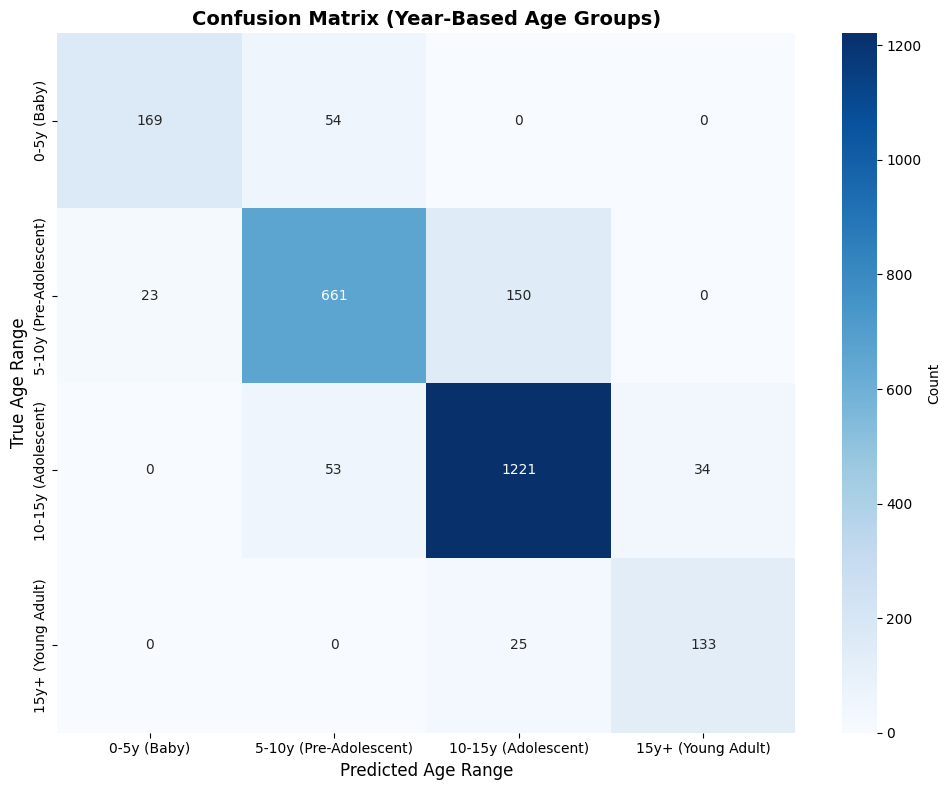

In [19]:
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, cohen_kappa_score
)

# Use predictions from previous cell (y_true and y_pred are in years)
# all_true and all_pred are in months (from inference loop)

# ============================================
# REGRESSION METRICS
# ============================================
print("\n" + "="*60)
print("REGRESSION METRICS (Years)")
print("="*60)
print(f"MAE:  {mae:.4f} years  ({mae*12:.2f} months)")
print(f"RMSE: {rmse:.4f} years ({rmse*12:.2f} months)")
print(f"R²:   {r2:.4f}")
print("="*60)

# ============================================
# CLASSIFICATION METRICS (Month-Based Bins)
# ============================================
AGE_BINS_MONTHS = [0, 60, 120, 180, 300]  # 0-5y, 5-10y, 10-15y, 15y+
AGE_LABELS = [0, 1, 2, 3]

# Bucket using months
actuals_months = np.array(all_true)
preds_months = np.array(all_pred)

y_test_cls = pd.cut(actuals_months, bins=AGE_BINS_MONTHS, labels=AGE_LABELS, include_lowest=True).astype(int)
pred_cls = pd.cut(preds_months, bins=AGE_BINS_MONTHS, labels=AGE_LABELS, include_lowest=True).astype(int)

# Calculate classification metrics
accuracy = accuracy_score(y_test_cls, pred_cls)
precision = precision_score(y_test_cls, pred_cls, average='macro', zero_division=0)
recall = recall_score(y_test_cls, pred_cls, average='macro', zero_division=0)
f1 = f1_score(y_test_cls, pred_cls, average='macro', zero_division=0)
qwk = cohen_kappa_score(y_test_cls, pred_cls, weights='quadratic')

print("\n" + "="*60)
print("CLASSIFICATION METRICS (Month-Based Age Groups)")
print("="*60)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"QWK:       {qwk:.4f}")
print("="*60)

# ============================================
# YEAR-BASED CLASSIFICATION
# ============================================
YEAR_BINS = [0, 5, 10, 15, 25]
YEAR_LABELS = ['0-5y (Baby)', '5-10y (Pre-Adolescent)', '10-15y (Adolescent)', '15y+ (Young Adult)']

# Bucket using years
y_true_cls = pd.cut(y_true, bins=YEAR_BINS, labels=YEAR_LABELS, include_lowest=True)
y_pred_cls = pd.cut(y_pred, bins=YEAR_BINS, labels=YEAR_LABELS, include_lowest=True)

# Classification Report
print("\n" + "="*60)
print("CLASSIFICATION REPORT (Year-Based Labels)")
print("="*60)
print(classification_report(y_true_cls, y_pred_cls))

# ============================================
# CONFUSION MATRIX VISUALIZATION
# ============================================
cm = confusion_matrix(y_true_cls, y_pred_cls, labels=YEAR_LABELS)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=YEAR_LABELS,
            yticklabels=YEAR_LABELS,
            cbar_kws={'label': 'Count'})
plt.title("Confusion Matrix (Year-Based Age Groups)", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Age Range", fontsize=12)
plt.ylabel("True Age Range", fontsize=12)
plt.tight_layout()
plt.show()